# This is the code for training the model

In [1]:
import detectron2
from detectron2.utils.logger import setup_logger
setup_logger()

import numpy as np
import os, json, cv2, random, re
from PIL import Image # Replacement for cv2_imshow
import json, glob

from detectron2 import model_zoo
from detectron2.engine import DefaultTrainer, DefaultPredictor
from detectron2.evaluation import COCOEvaluator, DatasetEvaluators
from detectron2.config import get_cfg
from detectron2.utils.visualizer import Visualizer
from detectron2.data import MetadataCatalog, DatasetCatalog

In [2]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.device_count())
print(torch.version.cuda)

True
1
11.8


If this does not say "True" or fails, reboot the computer. Trust.

In [3]:
# Define the one true category map
CATEGORY_MAP = {"root_hair": 1,}

THING_CLASSES = ["root_hair"]

CATEGORIES = [{"id": v, "name": k, "supercategory": "root_hair"} 
              for k, v in CATEGORY_MAP.items()]


In [4]:
print(CATEGORIES)

[{'id': 1, 'name': 'root_hair', 'supercategory': 'root_hair'}]


<h2>Register Datasets !! Important </h2>

In [5]:
from detectron2.data.datasets import register_coco_instances

# These determine what the model sees and trains on. Be cautios.
register_coco_instances("model2_train", {}, "model2_data/train.json", "/home/mellanie/Desktop/Annotated_dataset/")
register_coco_instances("model2.5_eval", {}, "model2.5_data/test.json", "/home/mellanie/Desktop/Annotated_dataset/")

<h3>Create trainer</h3>

In [6]:
class MyTrainer(DefaultTrainer):
    @classmethod
    def build_evaluator(cls, cfg, dataset_name, output_folder=None):
        if output_folder is None:
            output_folder = os.path.join(cfg.OUTPUT_DIR, "inference")
            print(output_folder)
        
        metadata = MetadataCatalog.get(dataset_name)
        return COCOEvaluator(
            dataset_name=dataset_name,
            output_dir=output_folder,
            distributed=False,
            use_fast_impl=True,
            tasks=["bbox", "segm"]  # or just ["segm"] depending on your needs
        )

<h3>Register datasets + train</h3>

In [7]:
cfg = get_cfg()
cfg.merge_from_file(model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_101_FPN_3x.yaml"))


custom_metadata = MetadataCatalog.get("custom_root_v2")
from detectron2.data import MetadataCatalog
MetadataCatalog.get("custom_root_v2").set(thing_classes=THING_CLASSES)

cfg.DATASETS.TRAIN = ("model2_train")

cfg.DATASETS.TEST = ("model2.5_eval",)
cfg.DATALOADER.NUM_WORKERS = 2
cfg.MODEL.WEIGHTS = model_zoo.get_checkpoint_url("COCO-InstanceSegmentation/mask_rcnn_R_101_FPN_3x.yaml")
cfg.SOLVER.IMS_PER_BATCH = 2
cfg.SOLVER.BASE_LR = 0.001
cfg.SOLVER.MAX_ITER = 5000   
cfg.SOLVER.STEPS = [3000, 4000]
cfg.SOLVER.GAMMA = 0.1
cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 512
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 1
cfg.MODEL.MASK_ON = True
cfg.SOLVER.CHECKPOINT_PERIOD = 500
cfg.MODEL.DEVICE = "cuda"  
cfg.MODEL.ROI_HEADS.NMS_THRESH_TEST = 0.5

os.makedirs(cfg.OUTPUT_DIR, exist_ok = True)
trainer = MyTrainer(cfg)
trainer.resume_or_load(resume = False)
trainer.train()

[08/12 14:08:16 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False
          (norm): FrozenBatchNorm2d(num_features=64, eps=1e-05)
        )
      )
      (res

Skip loading parameter 'roi_heads.box_predictor.cls_score.weight' to the model due to incompatible shapes: (81, 1024) in the checkpoint but (2, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.cls_score.bias' to the model due to incompatible shapes: (81,) in the checkpoint but (2,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.weight' to the model due to incompatible shapes: (320, 1024) in the checkpoint but (4, 1024) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.box_predictor.bbox_pred.bias' to the model due to incompatible shapes: (320,) in the checkpoint but (4,) in the model! You might want to double check if this is expected.
Skip loading parameter 'roi_heads.mask_head.predictor.weight' to the model due to incompatible shapes: (80, 256, 1, 1) in the checkpoint but (1, 256, 1, 1) in

[08/12 14:08:17 d2.engine.train_loop]: Starting training from iteration 0


/home/mellanie/.local/lib/python3.10/site-packages/torch/functional.py:554: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4314.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


[08/12 14:08:24 d2.utils.events]:  eta: 0:18:53  iter: 19  total_loss: 4.114  loss_cls: 0.623  loss_box_reg: 0.2861  loss_mask: 0.6895  loss_rpn_cls: 1.974  loss_rpn_loc: 0.5454    time: 0.2414  last_time: 0.2360  data_time: 0.0188  last_data_time: 0.0046   lr: 1.9981e-05  max_mem: 3199M
[08/12 14:08:28 d2.utils.events]:  eta: 0:18:27  iter: 39  total_loss: 1.976  loss_cls: 0.4484  loss_box_reg: 0.3208  loss_mask: 0.6833  loss_rpn_cls: 0.09682  loss_rpn_loc: 0.4202    time: 0.2316  last_time: 0.2228  data_time: 0.0057  last_data_time: 0.0052   lr: 3.9961e-05  max_mem: 3236M
[08/12 14:08:33 d2.utils.events]:  eta: 0:18:28  iter: 59  total_loss: 1.827  loss_cls: 0.3458  loss_box_reg: 0.2985  loss_mask: 0.6682  loss_rpn_cls: 0.07838  loss_rpn_loc: 0.3775    time: 0.2309  last_time: 0.2788  data_time: 0.0056  last_data_time: 0.0100   lr: 5.9941e-05  max_mem: 3236M
[08/12 14:08:38 d2.utils.events]:  eta: 0:18:29  iter: 79  total_loss: 1.867  loss_cls: 0.3674  loss_box_reg: 0.4099  loss_mask

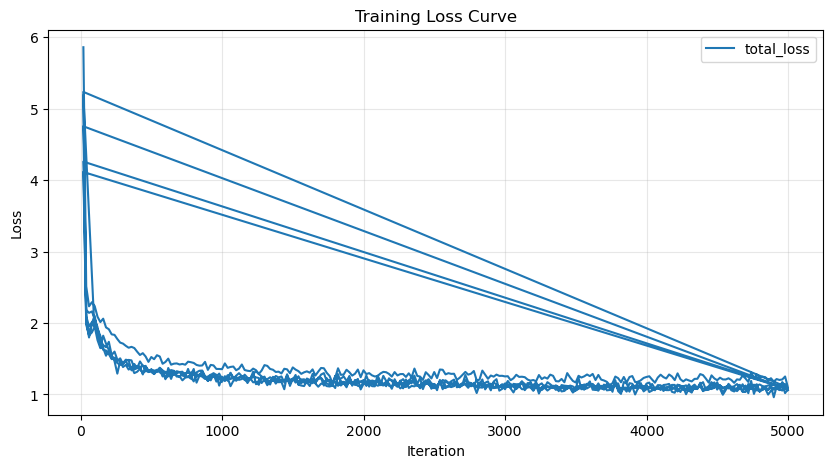

In [8]:
import json
import matplotlib.pyplot as plt

def load_metrics(output_dir):
    metrics_path = os.path.join(output_dir, "metrics.json")
    with open(metrics_path) as f:
        return [json.loads(line) for line in f]

metrics = load_metrics(cfg.OUTPUT_DIR)

iterations = [m["iteration"] for m in metrics if "total_loss" in m]
total_loss = [m["total_loss"] for m in metrics if "total_loss" in m]

plt.figure(figsize=(10, 5))
plt.plot(iterations, total_loss, label="total_loss")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Training Loss Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [9]:
import json
import glob

label_counts = {}

for json_file in glob.glob("/home/mellanie/Dessktop/Annotated_dataset/**/*.json", recursive=True):
    try:
        with open(json_file) as f:
            data = json.load(f)
        if "shapes" in data:  # LabelMe format
            for shape in data["shapes"]:
                label = shape["label"]
                label_counts[label] = label_counts.get(label, 0) + 1
    except:
        pass

print("Labels found across all LabelMe files:")
for label, count in sorted(label_counts.items(), key=lambda x: x[1], reverse=True):
    print(f"  {label}: {count}")

Labels found across all LabelMe files:


<h3>Inference + Evaluation</h3>

In [10]:
cfg = get_cfg()
cfg.MODEL.WEIGHTS = "output/model_final.pth"
cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = .5

# Set correct metadata for visualisation
custom_metadata = MetadataCatalog.get("custom_root_v2")
custom_metadata.thing_classes = THING_CLASSES
# cfg.MODEL.DEVICE = "cpu" 
predictor = DefaultPredictor(cfg)

[08/12 14:29:32 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from output/model_final.pth ...


Skip loading parameter 'proposal_generator.rpn_head.conv.weight' to the model due to incompatible shapes: (256, 256, 3, 3) in the checkpoint but (1024, 1024, 3, 3) in the model! You might want to double check if this is expected.
Skip loading parameter 'proposal_generator.rpn_head.conv.bias' to the model due to incompatible shapes: (256,) in the checkpoint but (1024,) in the model! You might want to double check if this is expected.
Skip loading parameter 'proposal_generator.rpn_head.objectness_logits.weight' to the model due to incompatible shapes: (3, 256, 1, 1) in the checkpoint but (15, 1024, 1, 1) in the model! You might want to double check if this is expected.
Skip loading parameter 'proposal_generator.rpn_head.objectness_logits.bias' to the model due to incompatible shapes: (3,) in the checkpoint but (15,) in the model! You might want to double check if this is expected.
Skip loading parameter 'proposal_generator.rpn_head.anchor_deltas.weight' to the model due to incompatible s

In [11]:
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.data import build_detection_test_loader